In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [29]:
df = pd.read_csv("Exxonmobil Holdings (XOM) Historical Data.csv")
df

,Date,Price,Open,High,Low,Vol.,Change %
0,29/09/2026,161.35,160.22,161.96,159.27,9.16M,-0.72%
1,28/09/2026,162.52,162.80,163.54,161.05,12.81M,1.20%
2,25/09/2026,160.59,160.23,161.79,159.78,11.00M,-0.96%
3,24/09/2026,162.14,163.05,164.91,161.20,12.48M,0.56%
4,23/09/2026,161.23,159.62,162.12,159.42,12.58M,1.59%
...,...,...,...,...,...,...,...
2528,07/09/2016,88.24,88.65,88.67,87.97,7.47M,-0.37%
2529,06/09/2016,88.57,87.84,88.64,87.66,9.85M,1.32%
2530,02/09/2016,87.42,87.42,87.58,86.93,7.10M,0.67%
2531,01/09/2016,86.84,86.72,86.84,86.09,8.43M,-0.34%


In [30]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
df

C:\Users\Invate\AppData\Local\Temp\ipykernel_16380\3782568401.py:1: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Date"] = pd.to_datetime(df["Date"])


,Date,Price,Open,High,Low,Vol.,Change %
0,2016-08-31,87.14,87.14,87.21,86.22,12.49M,-0.43%
1,2016-09-01,86.84,86.72,86.84,86.09,8.43M,-0.34%
2,2016-09-02,87.42,87.42,87.58,86.93,7.10M,0.67%
3,2016-09-06,88.57,87.84,88.64,87.66,9.85M,1.32%
4,2016-09-07,88.24,88.65,88.67,87.97,7.47M,-0.37%
...,...,...,...,...,...,...,...
2528,2026-09-23,161.23,159.62,162.12,159.42,12.58M,1.59%
2529,2026-09-24,162.14,163.05,164.91,161.20,12.48M,0.56%
2530,2026-09-25,160.59,160.23,161.79,159.78,11.00M,-0.96%
2531,2026-09-28,162.52,162.80,163.54,161.05,12.81M,1.20%


In [31]:
df[["Date", "Price"]].head()


,Date,Price
0,2016-08-31,87.14
1,2016-09-01,86.84
2,2016-09-02,87.42
3,2016-09-06,88.57
4,2016-09-07,88.24


In [32]:
df[["Date", "Price"]].tail()

,Date,Price
2528,2026-09-23,161.23
2529,2026-09-24,162.14
2530,2026-09-25,160.59
2531,2026-09-28,162.52
2532,2026-09-29,161.35


In [33]:
print("Number of rows:", len(df))
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())
print("Duplicate rows:", df.duplicated().sum())
print("Missing prices:", df["Price"].isna().sum())

Number of rows: 2533
First date: 2016-08-31 00:00:00
Last date: 2026-09-29 00:00:00
Duplicate rows: 0
Missing prices: 0


Data Cleaning log:
The dates required conversion as they were in the format of strings meaning python does not view as dates.
The observations were ordered from newest to oldest.
There were no duplicate rows.
No missing or NaN entries in the data.
The only change i made was converting the dates given into datatime so that the data could be more easily plotted. 


In [34]:
print("Company: ExxonMobil Holdings Corporation ")
print("Ticker: XOM")
print("Exchange: NYSE")
print("Currency/unit: USD")
print("First trading date:", df["Date"].min())
print("Last trading date:", df["Date"].max())
print("Number of observations:", len(df))

Company: ExxonMobil Holdings Corporation 
Ticker: XOM
Exchange: NYSE
Currency/unit: USD
First trading date: 2016-08-31 00:00:00
Last trading date: 2026-09-29 00:00:00
Number of observations: 2533


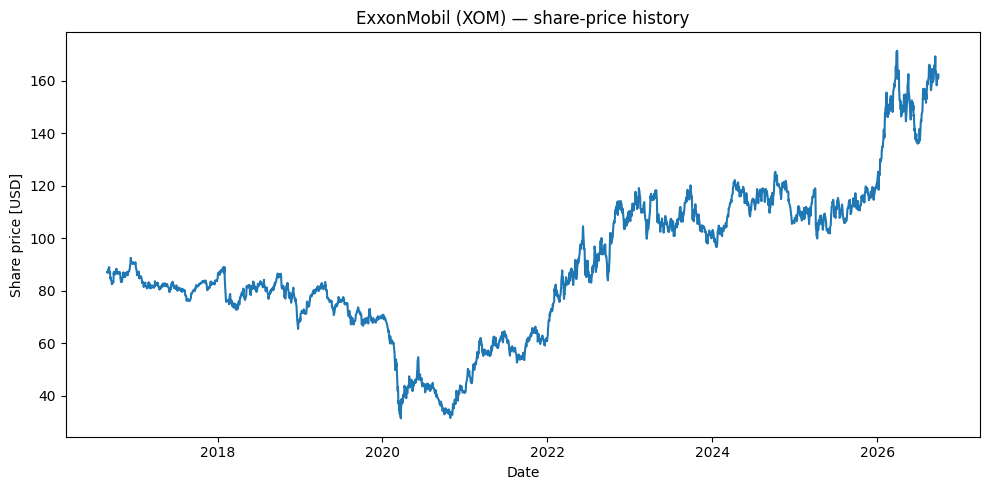

In [35]:
plt.figure(figsize=(10,5))
plt.plot(df["Date"], df["Price"])
plt.xlabel("Date")
plt.ylabel("Share price [USD]")
plt.title("ExxonMobil (XOM) — share-price history")
plt.tight_layout()
plt.show()

The ExxonMobil stock shows a downward trend from 2016 to 2020, reaching its lowest price at around $30-$40 during 2020. 
From 2021, the share price increases strongly, with large positive movements between 2021 and 2023 and again during 2026.
The highest prices occur near 2026, where the share price reaches approximately $170.

In [36]:
r = 0.0375
T = 2 / 12

df['Forward_Price'] = df['Price'] * np.exp(r * T)
latest_row = df.iloc[-1]
latest_row

Date             2026-09-29 00:00:00
Price                         161.35
Open                          160.22
High                          161.96
Low                           159.27
Vol.                           9.16M
Change %                      -0.72%
Forward_Price             162.361595
Name: 2532, dtype: object

In [37]:
S_0 = latest_row["Price"]
date_S0 = latest_row["Date"]

print(f"S_0 = {S_0}")
print(f"Date of S_0 = {date_S0}")
print("Price unit/currency = USD")

S_0 = 161.35
Date of S_0 = 2026-09-29 00:00:00
Price unit/currency = USD


In [38]:
F0T = S_0 * np.exp(r*T)
print("Spot price =", S_0)
print("Forward price =", F0T)

Spot price = 161.35
Forward price = 162.361595442807


In [39]:
growth_factor = np.exp(r*T)
print(growth_factor)

1.006269572003762


1) The forward price is about $1.01 higher than the current share price.
2) Since the growth factor = 1.006269 which is greater than 1 it causes the forward price to exceed the current spot price
3) The risk free rate determines how quickly the spot price grows when calculating the forward price.
A higher risk-free rate creates a higher forward price.
4) Maturity determines how long the spot price is compounded. A longer maturity the bigger the difference between the spot and forward prices will be.

Using the Week 1 no-arbitrage model, the two-month forward delivery price for ExxonMobil (XOM) is approximately 162.36 USD per share, compared with a spot/reference price of 161.35 USD per share on 29 September 2026. The forward price is slightly higher because the model includes the positive financing cost of carrying the stock over the two-month period at the risk-free rate. This is a no-arbitrage benchmark under the stated assumptions; it is not a forecast that ExxonMobil shares will actually trade at 162.36 USD in two months.

In [40]:
cash_carry = pd.DataFrame({
    "Time": ["t = 0", "t = 0", "t = 0", "T", "T", "T"],
    "Action": [
        "Borrow 161.35 USD",
        "Buy one ExxonMobil share",
        "Short the two-month forward at K = 165.00 USD", #this is an example
        "Deliver the share into the short forward",
        "Repay borrowing with continuous interest",
        "Risk-free model profit"
    ],
    "Cash-flow logic": [
        "+161.35 USD",
        "-161.35 USD",
        "Zero initial value in the simple model",
        "Receive 165.00 USD",                      
        "Repay 162.36 USD",
        "165.00 - 162.36 = 2.64 USD per share"
    ]
})

cash_carry

,Time,Action,Cash-flow logic
0,t = 0,Borrow 161.35 USD,+161.35 USD
1,t = 0,Buy one ExxonMobil share,-161.35 USD
2,t = 0,Short the two-month forward at K = 165.00 USD,Zero initial value in the simple model
3,T,Deliver the share into the short forward,Receive 165.00 USD
4,T,Repay borrowing with continuous interest,Repay 162.36 USD
5,T,Risk-free model profit,165.00 - 162.36 = 2.64 USD per share


In [ ]:
rates = [0.02, 0.0375, 0.05]
results = []

for rate in rates:
    F = S_0 * np.exp(rate * T)
    results.append([rate, F])

forward_table = pd.DataFrame(
    results,
    columns=["Risk-free rate", "Forward price (USD)"]
)

forward_table

,Risk-free rate,Forward price (USD)
0,0.0200,161.888731
1,0.0375,162.361595
2,0.0500,162.700201


As the risk-free rate increases, the forward price​ also increases rising from approximately 161.89 USD at 2.0% to 162.70 USD at 5.0%. This makes financial sense because a higher risk-free rate increases the financing cost of holding the share until maturity, which leads to a higher no-arbitrage forward price under the model.

In [ ]:
Week 2 — Returns, volatility and options

In [45]:
df["LogReturn"] = np.log(df["Price"] / df["Price"].shift(1))
df[["Date", "Price", "LogReturn"]].head()
df

,Date,Price,Open,High,Low,Vol.,Change %,Forward_Price,LogReturn
0,2016-08-31,87.14,87.14,87.21,86.22,12.49M,-0.43%,87.686331,NaN
1,2016-09-01,86.84,86.72,86.84,86.09,8.43M,-0.34%,87.384450,-0.003449
2,2016-09-02,87.42,87.42,87.58,86.93,7.10M,0.67%,87.968086,0.006657
3,2016-09-06,88.57,87.84,88.64,87.66,9.85M,1.32%,89.125296,0.013069
4,2016-09-07,88.24,88.65,88.67,87.97,7.47M,-0.37%,88.793227,-0.003733
...,...,...,...,...,...,...,...,...,...
2528,2026-09-23,161.23,159.62,162.12,159.42,12.58M,1.59%,162.240843,0.015753
2529,2026-09-24,162.14,163.05,164.91,161.20,12.48M,0.56%,163.156548,0.005628
2530,2026-09-25,160.59,160.23,161.79,159.78,11.00M,-0.96%,161.596831,-0.009606
2531,2026-09-28,162.52,162.80,163.54,161.05,12.81M,1.20%,163.538931,0.011947


The first log return is missing (NaN) because there is no previous price to compare it with. The caluculation for log return requires 
the current price and the previous price. 
The dates need to be sorted from oldest to newest so that each return measures the change from the previous day to the current day. If the dates are from newest to oldest, the calculation will compare today's price to a future price.
A positive log return means the share price increased between the two dates that are consecutive. A negative log return means the share price decreased between two dates that are consecutive.

In [44]:
returns = df["LogReturn"].dropna()

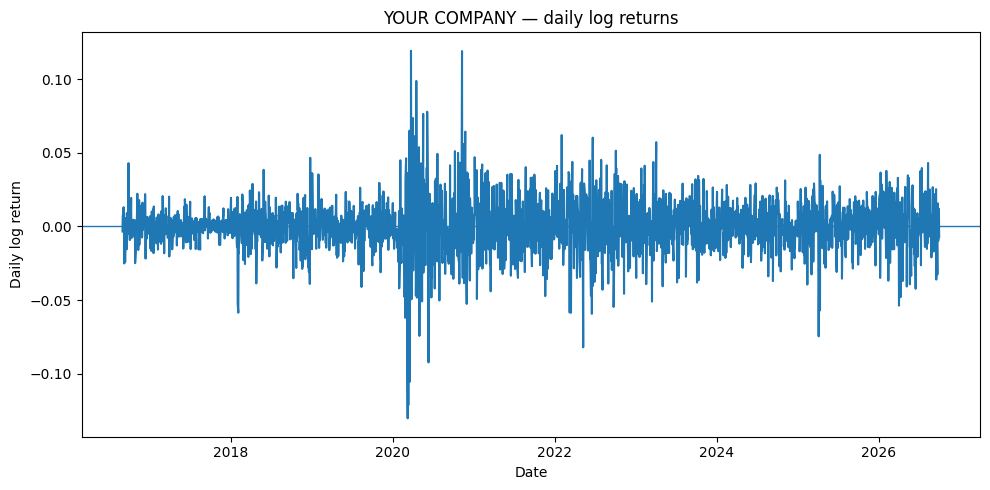

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(df["Date"], df["LogReturn"])
plt.axhline(0, linewidth=1)
plt.xlabel("Date")
plt.ylabel("Daily log return")
plt.title("ExxonMobil — daily log returns")
plt.tight_layout()
plt.show()

The daily log returns fluctuate around zero, with most observations clustered close to the horizontal axis and no obvious long term upward or downward drift. The largest positive return appears to be slightly above 0.10, while the largest negative return is approximately −0.13, with both occurring around 2020.
The plot shows periods of calm returns followed by periods of much larger fluctuations. The volatility increases around 2020 where large positive and negative returns occur close together. This pattern provides visual evidence consistent with volatility clustering, as periods of high volatility tend to be followed by further periods of high volatility rather than immediately returning to a calm state

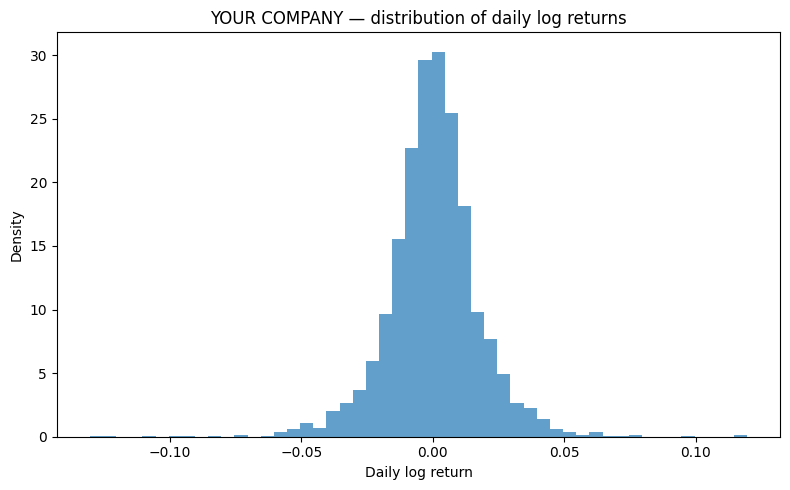

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(returns, bins=50, density=True, alpha=0.7)
plt.xlabel("Daily log return")
plt.ylabel("Density")
plt.title("ExxonMobil — distribution of daily log returns")
plt.tight_layout()
plt.show()

In [49]:
mean_daily = returns.mean()
std_daily = returns.std(ddof=1)
print("Mean daily log return =", mean_daily)
print("Daily standard deviation =", std_daily)
print("Minimum daily log return =", returns.min())
print("Maximum daily log return =", returns.max())

Mean daily log return = 0.00024330959629094496
Daily standard deviation = 0.01793319695913128
Minimum daily log return = -0.13039101529227934
Maximum daily log return = 0.11944214259043069


The distribution of daily log returns is centred very close to zero, with a mean daily log return of approximately 0.00024, indicating no strong tendency towards positive or negative returns over the sample period. The histogram appears reasonably symmetric around zero, although the negative side is slightly longer than the positive side, as the minimum return (-0.130) has a greater magnitude than the maximum return (0.119).

There are several extreme observations in both tails of the distribution, so despite it apprearing to look like a Normal graph I would not describe it as Normal.

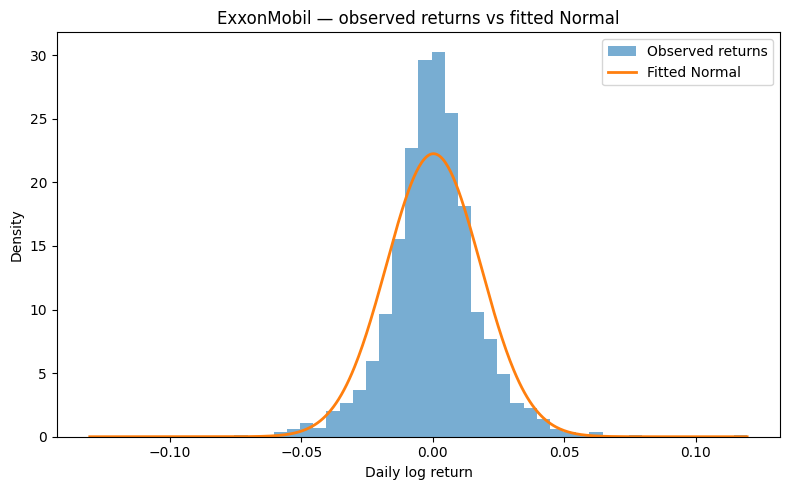

In [50]:
from scipy.stats import norm
mu = returns.mean()
s = returns.std(ddof=1)
x = np.linspace(returns.min(), returns.max(), 500)
plt.figure(figsize=(8,5))
plt.hist(returns, bins=50, density=True, alpha=0.6, label="Observed returns")
plt.plot(x, norm.pdf(x, loc=mu, scale=s), linewidth=2, label="Fitted Normal")
plt.xlabel("Daily log return")
plt.ylabel("Density")
plt.title("ExxonMobil — observed returns vs fitted Normal")
plt.legend()
plt.tight_layout()
plt.show()

The fitted Normal distribution provides a reasonably good description of the centre of the return distribution, as both the histogram and the Normal curve are centred close to zero and have a similar overall bell shape around the mean. 
However, the fit appears less accurate in the tails of the distribution. The histogram shows several extreme positive and negative returns that occur more frequently and extend further from zero than would be expected under a Normal distribution.
The figure does not support the conclusion that daily returns are exactly Normally distributed.

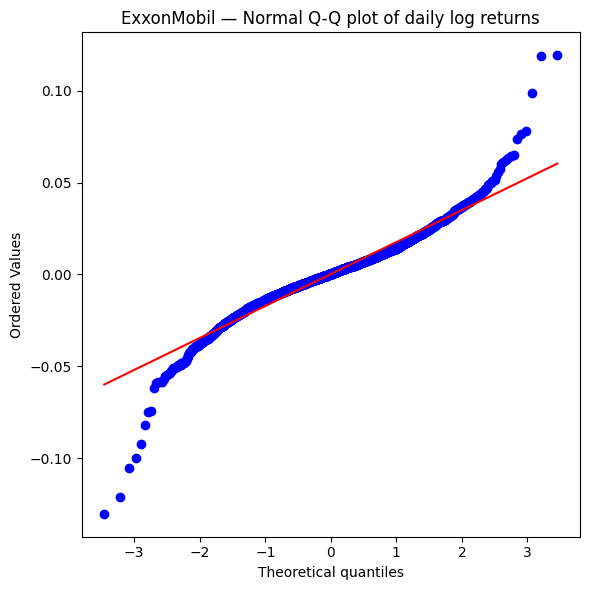

In [51]:
from scipy import stats
plt.figure(figsize=(6,6))
stats.probplot(returns, dist="norm", plot=plt)
plt.title("ExxonMobil — Normal Q-Q plot of daily log returns")
plt.tight_layout()
plt.show()

The middle quantiles lie close to the reference line, this suggests that a Normal distribution provides a good approximation to the central part of the return distribution. This is consistent with the histogram, where most observations are concentrated around zero. In the lower tail, the points fall  below and the upper tail bends away, showing more extreme observations than the Normal approximation predicts. 
Taken together with the histogram, the Q-Q plot suggests that a Normal distribution is a good approximation for the centre of the return distribution but does not capture the tails well.

In [54]:
summary_table = pd.DataFrame({
    "Measure": [
        "Annualised mean log return",
        "Annualised historical volatility"
    ],
    "Decimal": [
        mean_log_return_annual,
        sigma_annual
    ],
    "Percentage": [
        mean_log_return_annual * 100,
        sigma_annual * 100
    ]
})

summary_table["Decimal"] = summary_table["Decimal"].round(4)
summary_table["Percentage"] = summary_table["Percentage"].round(2)

summary_table

,Measure,Decimal,Percentage
0,Annualised mean log return,0.0613,6.13
1,Annualised historical volatility,0.2847,28.47


The annualised mean log return of 6.13% is the average rate of growth in ExxonMobil's share price over the sample period, expressed on an annual basis using continuously compounded returns. The annualised historical volatility of 28.47% measures the typical variability of returns around their average and provides an indication of the share's historical risk.

Volatility is calculated from returns because return changes are comparable through time and across price levels; the raw
share-price level itself is non-stationary and its standard deviation would depend strongly on the price scale.

In [55]:
# Example: most recent 1 year relative to the final date in your dataset
end_date = df["Date"].max()
start_recent = end_date - pd.DateOffset(years=1)
recent = df.loc[df["Date"] >= start_recent, "LogReturn"].dropna()
recent_mean_annual = recent.mean() * 252
recent_sigma_annual = recent.std(ddof=1) * np.sqrt(252)
print("Full-sample annualised mean log return =", mean_log_return_annual)
print("Recent annualised mean log return =", recent_mean_annual)
print("Full-sample annualised volatility =", sigma_annual)
print("Recent annualised volatility =", recent_sigma_annual)

Full-sample annualised mean log return = 0.06131401826531813
Recent annualised mean log return = 0.3195234074496881
Full-sample annualised volatility = 0.2846806761972067
Recent annualised volatility = 0.2606280642360543


The recent two-year period produced a substantially higher annualised mean log return of approximately 31.95%, compared with 6.13% for the full ten-year sample.
The annualised historical volatility of the recent period was approximately 26.06%, compared with 28.47% for the full sample. This suggests that recent returns were slightly less volatile than those observed over the full ten-year history, although the difference of around 2.4 percentage points is relatively modest compared with the much larger difference in average returns.

S0 = 161.35 USD per share
K  = 165.00 USD per share

T = 2/12 years
r = 0.0375
Price unit/currency = USD per share

Use S₀ = 161.35 USD per share, T = 2/12 years and r = 0.0375. A convenient and defensible strike is K = 165.00 USD per share. This is only 3.65 USD (about 2.26%) above the reference spot price, so it is close to at-the-money while remaining a simple round strike. The matched call is therefore slightly out-of-the-money at inception and the matched put slightly in-the-money.

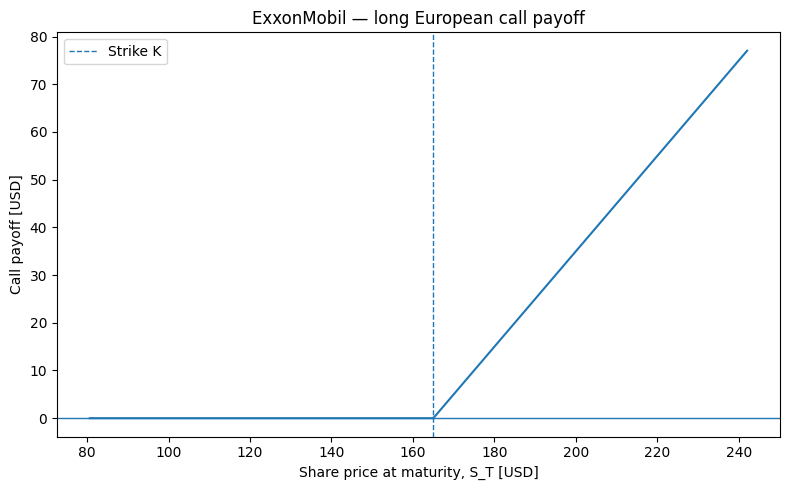

In [62]:
K  = 165.00

ST = np.linspace(0.5*S_0, 1.5*S_0, 400)
call_payoff = np.maximum(ST - K, 0)
plt.figure(figsize=(8,5))
plt.plot(ST, call_payoff)
plt.axhline(0, linewidth=1)
plt.axvline(K, linestyle="--", linewidth=1, label="Strike K")
plt.xlabel("Share price at maturity, S_T [USD]")
plt.ylabel("Call payoff [USD]")
plt.title("ExxonMobil — long European call payoff")
plt.legend()
plt.tight_layout()
plt.show()

The European call option will be exercised whenever the share price at maturity exceeds the strike price 165.00 USD.
The call payoff is zero when the market price is below or equal to the strike price.
The call is in-the-money at maturity when the market price of ExxonMobil shares exceeds the strike price.

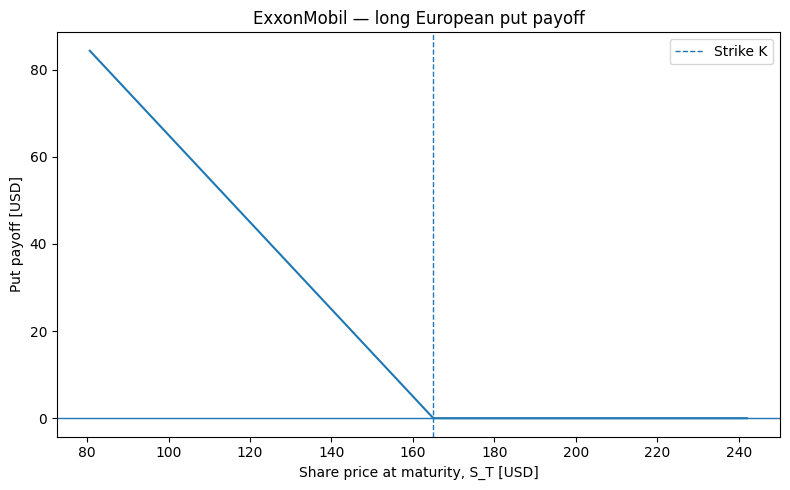

In [64]:
put_payoff = np.maximum(K - ST, 0)
plt.figure(figsize=(8,5))
plt.plot(ST, put_payoff)
plt.axhline(0, linewidth=1)
plt.axvline(K, linestyle="--", linewidth=1, label="Strike K")
plt.xlabel("Share price at maturity, S_T [USD]")
plt.ylabel("Put payoff [USD]")
plt.title("ExxonMobil — long European put payoff")
plt.legend()
plt.tight_layout()
plt.show()

In [66]:
r = 0.0375
T = 2/12
parity_rhs = S_0 - K*np.exp(-r*T)
print("S_0 - K exp(-rT) =", parity_rhs)

S_0 - K exp(-rT) = -2.621965952860137


In [68]:
# Parameters to carry into Week 3
S0 = 161.35 # final/reference share price from Week 1
K = 165.00 # strike chosen in Week 2
r = 0.0375 # coursework rate, continuously compounded
T = 2/12 # two-month maturity in years
sigma = sigma_annual # historical volatility estimated in Week 2
print("S0 =", S0)
print("K =", K)
print("r =", r)
print("T =", T)
print("sigma =", sigma)

S0 = 161.35
K = 165.0
r = 0.0375
T = 0.16666666666666666
sigma = 0.2846806761972067
